# Chapter 3 · Going 2D: transport fields and the ensemble Kalman filter
**Level: Advanced** · ~60 min · 2D

The 1D rod taught the method. Now the asset is a **stirred water tank** (or a ventilated room)
with a contaminant concentration $c(x, y, t)$. Two new difficulties appear:
1. **Transport.** The fluid *carries* the contaminant. Fields develop swirls, filaments and
   sharp fronts, which are much harder to model and to sense than the smooth bumps of a rod.
2. **Size.** A 48×48 field has 2,304 numbers. The Kalman covariance $P$ would have 5.3 million
   entries and be far too expensive to propagate. And the unknown physics parameters enter the
   model nonlinearly.

| Part | Topic |
|---|---|
| **A** | the advection-diffusion equation, solving it in 2D, the Péclet number, a leak, mass balance |
| **B** | the ensemble Kalman filter (EnKF): a 2D twin that tracks the field and learns its own physics |

**Prerequisites:** Chapters 1–2 (finite differences, $H$, the Kalman update).

## Glossary for this chapter
| Term | Meaning |
|---|---|
| **advection** | being carried along by a flow, like smoke in the wind |
| **diffusion** | spreading from high to low concentration, like the heat in Chapter 1 |
| **velocity field** $\mathbf v(x,y)$ | the flow's direction and speed at every point |
| **stream function** $\psi$ | a scalar whose contour lines are the flow's streamlines |
| **Péclet number** Pe | advection strength divided by diffusion strength |
| **finite volume** | a scheme that tracks how much material flows across each cell face, so mass is conserved exactly |
| **ensemble** | a set of $N$ model runs, each a plausible version of reality |
| **inflation** | artificially widening the ensemble so it doesn't become over-confident |
| **localization** | ignoring correlations between points far apart, which a small ensemble gets wrong |

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import AdvDiff2D, gaussian_blob, random_blobs, smooth_noise
from dtwin.sensors import PointSensors, grid_2d, flat_to_xy
from dtwin.assimilation import EnKF, gaspari_cohn
viz.set_style()

---
# Part A · The 2D physics: advection-diffusion

$$\frac{\partial c}{\partial t} + \underbrace{a\,\mathbf{v}\cdot\nabla c}_{\text{advection}} = \underbrace{\kappa\,\nabla^2 c}_{\text{diffusion}} - \underbrace{\lambda c}_{\text{decay}} + \underbrace{s(x,y,t)}_{\text{source}}$$

Read it term by term:
* $\partial c/\partial t$: how fast the concentration changes at a fixed point
* $a\,\mathbf v\cdot\nabla c$: the flow brings in water from upstream. If upstream is dirtier, the
  point gets dirtier. $a$ is the pump strength and $\mathbf v$ the flow pattern.
* $\kappa\nabla^2 c = \kappa(c_{xx} + c_{yy})$: diffusion, the 2D version of Chapter 1's curvature term
* $\lambda c$: removal, for example by a treatment filter or a chemical reaction
* $s$: sources, such as an inlet or a leak

## A1. From 1D to 2D: the grid, flattening, and the 5-point Laplacian
The field lives on an $n\times n$ grid of cells. For linear algebra we **flatten** it into one
long state vector, row by row: cell $(i_y, i_x)$ becomes entry $k = i_y\,n + i_x$. In 2D the
Laplacian couples each cell to its **four** neighbours:

$$\nabla^2 c \approx \frac{c_{E} + c_{W} + c_{N} + c_{S} - 4c_{P}}{\Delta x^2}$$

In [2]:
n_demo = 4
grid_idx = np.arange(n_demo * n_demo).reshape(n_demo, n_demo)
print("2D cell (iy, ix) -> flat index k = iy*n + ix:\n", grid_idx)
print("cell (1, 2) has k =", grid_idx[1, 2], "; its neighbours N/S/W/E have k =",
      grid_idx[0, 2], grid_idx[2, 2], grid_idx[1, 1], grid_idx[1, 3])

# verification: sin(pi x) sin(pi y) is an eigenfunction, Laplacian = -2 pi^2 * f
for n_ in [16, 32, 64]:
    xc = (np.arange(n_) + 0.5) / n_; h = 1 / n_
    F = np.sin(np.pi * xc)[None, :] * np.sin(np.pi * xc)[:, None]
    Fp = np.pad(F, 1, mode="constant")
    lap = (Fp[1:-1, 2:] + Fp[1:-1, :-2] + Fp[2:, 1:-1] + Fp[:-2, 1:-1] - 4 * F) / h**2
    inner = slice(n_ // 4, 3 * n_ // 4)
    print(f"n = {n_:3d}: max interior error of the 5-point Laplacian = "
          f"{np.abs(lap + 2*np.pi**2*F)[inner, inner].max():.4f}")

2D cell (iy, ix) -> flat index k = iy*n + ix:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
cell (1, 2) has k = 6 ; its neighbours N/S/W/E have k = 2 10 5 7
n =  16: max interior error of the 5-point Laplacian = 0.0627
n =  32: max interior error of the 5-point Laplacian = 0.0158
n =  64: max interior error of the 5-point Laplacian = 0.0040


✅ **Check:** the error drops by about 4× each time $n$ doubles. It is the same second-order
behaviour as in 1D, now in two directions.

## A2. Advection: being carried by the flow
Take pure advection in 1D, $c_t + U c_x = 0$. The exact solution just **slides** the profile at
speed $U$ without changing its shape. Numerically there's a catch: a cell should take its new value
from **upstream**, where the fluid comes from. This is the **upwind** rule. It is stable, but it
**smears** sharp features a little. That artificial smearing is called *numerical diffusion*, and
A7 measures it in 2D.

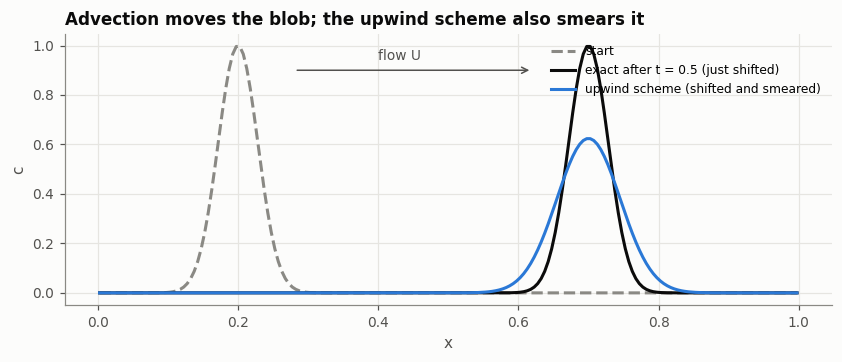

In [3]:
nx1 = 200; xg1 = (np.arange(nx1) + 0.5) / nx1; h1 = 1 / nx1
U1 = 1.0; dt1 = 0.5 * h1 / U1                     # Courant number U dt / h = 0.5
c_up = np.exp(-((xg1 - 0.2) / 0.04) ** 2)
c0_1 = c_up.copy()
n1 = int(0.5 / dt1)
for _ in range(n1):
    c_up = c_up - U1 * dt1 / h1 * (c_up - np.roll(c_up, 1))   # upwind: difference with the left (upstream) cell
exact1 = np.exp(-((xg1 - 0.2 - U1 * n1 * dt1) / 0.04) ** 2)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(xg1, c0_1, color=viz.MUTED, ls="--", label="start")
ax.plot(xg1, exact1, color=viz.TRUTH, label="exact after t = 0.5 (just shifted)")
ax.plot(xg1, c_up, color=viz.TWIN, label="upwind scheme (shifted and smeared)")
ax.annotate("", xy=(0.62, 0.9), xytext=(0.28, 0.9), arrowprops=dict(arrowstyle="->", color=viz.INK2))
ax.text(0.4, 0.94, "flow U", color=viz.INK2, fontsize=9)
ax.set(xlabel="x", ylabel="c", title="Advection moves the blob; the upwind scheme also smears it")
ax.legend(fontsize=8, loc="upper right")
plt.show()

Our 2D solver `AdvDiff2D` uses **finite volumes**: it computes the *flux* of contaminant
through each cell face (velocity × upwind concentration) and moves exactly that amount from one
cell to the next. Whatever leaves one cell enters its neighbour, so total mass is conserved to
machine precision. A6 checks this.

## A3. The stirring flow
A **cellular flow** from the stream function $\psi = \sin(\pi x)\sin(\pi y)$, with velocity
$(u, v) = (\partial_y\psi, -\partial_x\psi)$. It is divergence-free (incompressible) and has zero
normal velocity at the walls.

grid 96x96, dt = 0.0136, max speed = 0.063, Pe = 63


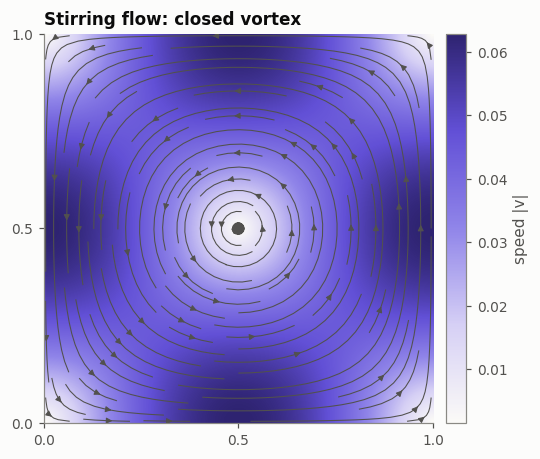

In [4]:
tank = AdvDiff2D(n=96, kappa=1e-3, flow_amplitude=0.02)
X, Y = tank.X, tank.Y
speed = tank.flow_amplitude * np.hypot(tank.U, tank.V)
print(f"grid {tank.n}x{tank.n}, dt = {tank.dt:.4f}, max speed = {speed.max():.3f}, "
      f"Pe = {speed.max() * 1.0 / tank.kappa:.0f}")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
viz.field(ax, speed, cmap=viz.UNCERTAINTY, label="speed |v|", title="Stirring flow: closed vortex")
ax.streamplot(tank.x, tank.x, tank.U, tank.V, color=viz.INK2, density=1.1, linewidth=0.7, arrowsize=0.8)
plt.show()

## A4. Diffusion vs. advection: the same blob, three Péclet numbers

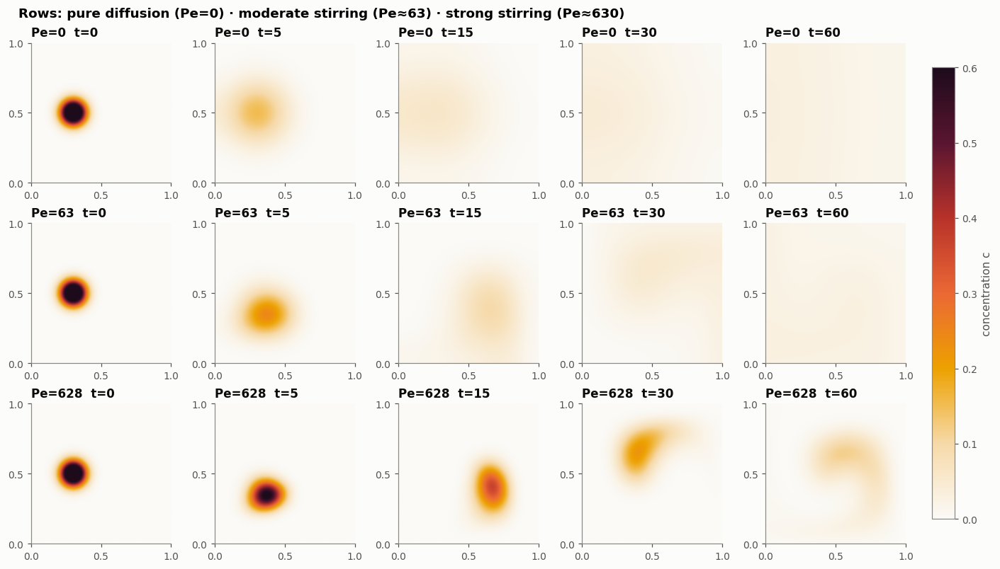

In [5]:
c0 = gaussian_blob(X, Y, 0.3, 0.5, width=0.06)
times = [0, 5, 15, 30, 60]
rows, labels = [], []
for kappa, amp in [(2e-3, 0.0), (1e-3, 0.02), (1e-4, 0.02)]:
    m = AdvDiff2D(n=96, kappa=kappa, flow_amplitude=amp)
    ts, C = m.simulate(c0, times[-1], save_every=1)
    pick = [np.argmin(abs(ts - tt)) for tt in times]
    rows += [C[p] for p in pick]
    pe = amp * np.pi / kappa
    labels += [f"Pe={pe:.0f}  t={tt}" for tt in times]

fig, axes = viz.snapshot_grid(rows, labels, ncols=5, vmin=0, vmax=0.6, label="concentration c",
                              size=2.4, suptitle="Rows: pure diffusion (Pe=0) · moderate stirring (Pe≈63) · strong stirring (Pe≈630)")
viz.save(fig, "05_peclet.png")
plt.show()

At high Pe the blob is stretched into a **spiral filament** before diffusion can smooth it.
A twin of such a flow needs denser sensors or smarter estimation; we revisit this in Part B and Chapter 4.

## A5. A leak: continuous source, probes, and arrival times
A leak starts at $(0.25, 0.3)$ at $t=0$ and stops at $t=20$. Four probes record concentration.

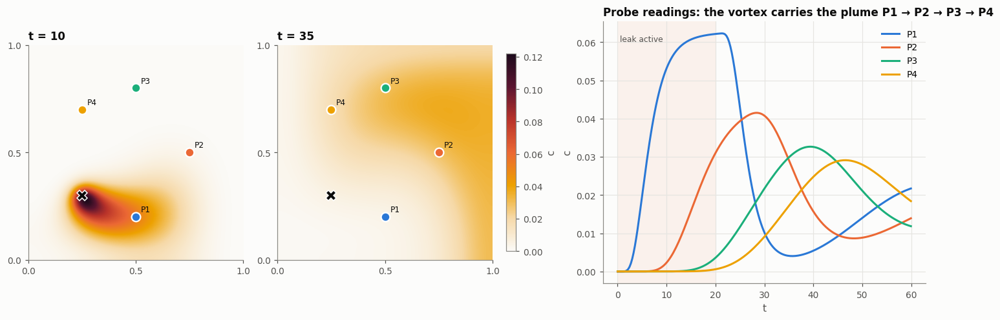

In [6]:
leak_xy = (0.25, 0.3)
leak = gaussian_blob(X, Y, *leak_xy, width=0.03, amp=0.15)
src = lambda t: leak if t < 20 else None
ts, C = tank.simulate(np.zeros_like(X), 60, source=src, save_every=20)

probes = {"P1": (0.5, 0.2), "P2": (0.75, 0.5), "P3": (0.5, 0.8), "P4": (0.25, 0.7)}
pidx = {k: (np.argmin(abs(tank.x - py)), np.argmin(abs(tank.x - px))) for k, (px, py) in probes.items()}

fig = plt.figure(figsize=(13, 4.4), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.5])
for j, tt in enumerate([10, 35]):
    ax = fig.add_subplot(gs[j])
    k = np.argmin(abs(ts - tt))
    viz.field(ax, C[k], vmin=0, vmax=C.max(), cbar=(j == 1), label="c", title=f"t = {ts[k]:.0f}")
    ax.plot(*leak_xy, "X", color=viz.INK, ms=10, mec="white")
    for i, (name, (px, py)) in enumerate(probes.items()):
        ax.plot(px, py, "o", color=viz.SERIES[i], ms=9, mec="white", mew=1.5)
        ax.annotate(name, (px, py), xytext=(5, 5), textcoords="offset points", fontsize=8, color=viz.INK)
ax = fig.add_subplot(gs[2])
for i, (name, (iy, ix)) in enumerate(pidx.items()):
    ax.plot(ts, C[:, iy, ix], color=viz.SERIES[i], label=name)
ax.axvspan(0, 20, color=viz.ORANGE, alpha=0.07, lw=0)
ax.text(0.5, ax.get_ylim()[1] * 0.92, "leak active", color=viz.INK2, fontsize=8)
ax.set(xlabel="t", ylabel="c", title="Probe readings: the vortex carries the plume P1 → P2 → P3 → P4")
ax.legend()
viz.save(fig, "05_leak_probes.png")
plt.show()

In [7]:
anim = viz.animate_2d([C[::2]], ts[::2], ["Leak in a stirred tank"], vlims=[(0, C.max())], size=4.2,
                      sensors=(np.array([p[0] for p in probes.values()]), np.array([p[1] for p in probes.values()])),
                      label="c")
HTML(anim.to_jshtml())

## A6. Mass balance
With zero-flux walls and no decay, total mass $\int c\,dA$ must grow exactly by what the leak injects.

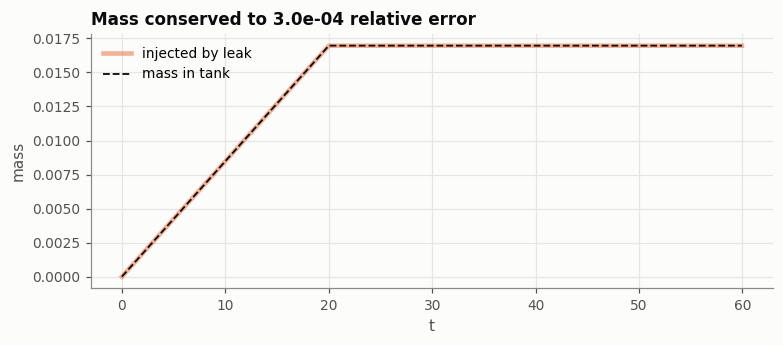

In [8]:
tfine, Cfine = tank.simulate(np.zeros_like(X), 60, source=src, save_every=5)
mass = Cfine.sum((1, 2)) * tank.dx**2
injected = np.minimum(tfine, 20) * leak.sum() * tank.dx**2

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tfine, injected, color=viz.ORANGE, lw=3, alpha=0.5, label="injected by leak")
ax.plot(tfine, mass, color=viz.INK, lw=1.2, ls="--", label="mass in tank")
ax.set(xlabel="t", ylabel="mass", title=f"Mass conserved to {abs(mass[-1]-injected[-1])/injected[-1]:.1e} relative error")
ax.legend()
plt.show()

## A7. Expert note: numerical diffusion
First-order upwind advection adds an artificial diffusion $\kappa_{\text{num}}\approx U\Delta x/2$.
On a coarse grid it can exceed the physical $\kappa$: the model is *smoother* than reality. A twin
calibrated on a coarse grid will therefore learn a **too-small κ**, because calibration silently
compensates for discretisation error. Grid convergence studies are part of building a twin.

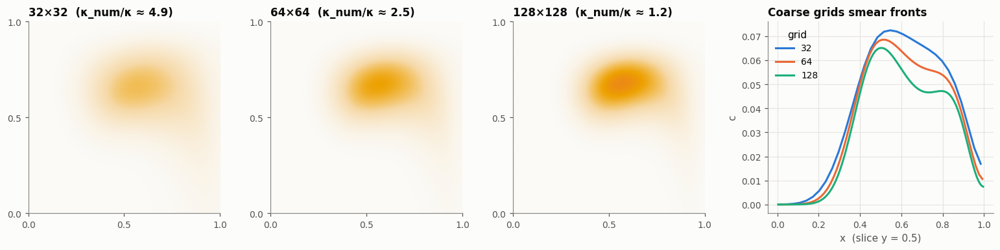

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), constrained_layout=True)
profiles = []
for ax, n in zip(axes[:3], [32, 64, 128]):
    m = AdvDiff2D(n=n, kappa=2e-4, flow_amplitude=0.02)
    c0n = gaussian_blob(m.X, m.Y, 0.3, 0.5, width=0.06)
    _, Cn = m.simulate(c0n, 25)
    viz.field(ax, Cn[-1], vmin=0, vmax=0.5, cbar=False, title=f"{n}×{n}  (κ_num/κ ≈ {0.02*np.pi*m.dx/2/2e-4:.1f})")
    j = n // 2
    profiles.append((m.x, Cn[-1][j]))
for i, (xx, p) in enumerate(profiles):
    axes[3].plot(xx, p, color=viz.SERIES[i], label=["32", "64", "128"][i])
axes[3].set(xlabel="x  (slice y = 0.5)", ylabel="c", title="Coarse grids smear fronts")
axes[3].legend(title="grid")
plt.show()

## Part A summary
* 2D fields are flattened into state vectors; the Laplacian becomes a 5-point stencil.
* Advection carries, diffusion smooths, and the **Péclet number** says which wins.
* Visualise with snapshot grids (structure), probe time series (what sensors see) and animations
  (dynamics).
* Validate with conservation laws, and remember the solver's own numerical diffusion when you
  calibrate $\kappa$.

---
# Part B · The ensemble Kalman filter

## B0. The idea: let a crowd of simulations estimate the uncertainty
The Kalman filter needs the covariance $P$. Instead of computing it with matrix algebra, the
**EnKF** runs $N \approx 40$ copies of the model (the **ensemble**). Each member has slightly
different initial conditions and parameters, all plausible given what we know. Then:
* the **mean** of the ensemble is the twin's best estimate
* the **spread** of the ensemble is its uncertainty
* covariances come straight from the sample: $P \approx \frac{1}{N-1}\sum_i (x_i - \bar x)(x_i - \bar x)^\top$

Each step has two parts:
1. **Forecast:** run every member through the full *nonlinear* model, each with its own parameters.
2. **Analysis:** apply the Kalman update to every member, using a slightly perturbed copy of the
   data $y + \epsilon_i$ so that the spread stays statistically correct.

$$x_i^a = x_i^f + K\,(y + \epsilon_i - Hx_i^f),\qquad K = P^fH^\top(HP^fH^\top + R)^{-1}$$

**How does it learn a parameter it never measures?** Through correlation. Suppose members with a
larger diffusivity $\kappa$ predict lower peak readings. Then when the sensor reads low, the
update pushes every member's $\kappa$ **up**. No gradients and no adjoint code are needed: just the
ensemble statistics.

## B1. A toy you can see: learning one hidden parameter from one reading
A blob of contaminant diffuses for a while. The peak a probe sees falls as
$1/(1 + 4\kappa t/w^2)$. We don't know $\kappa$; the prior says somewhere around $1.5\times10^{-3}$
± 40%. One reading arrives.

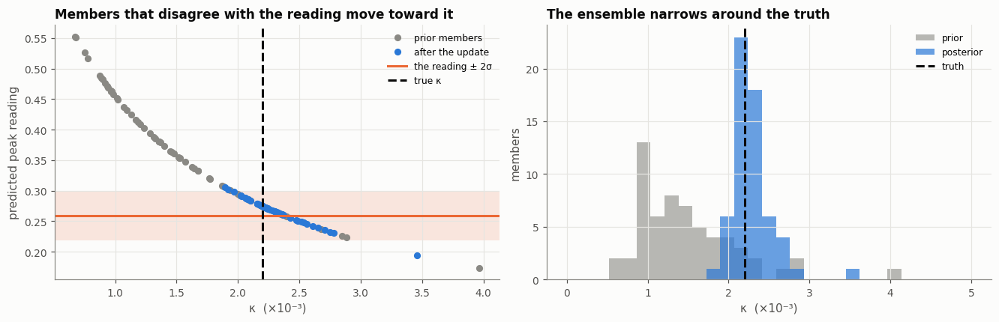

prior   kappa = 1.50 ± 0.62  (x1e-3)
after   kappa = 2.30 ± 0.24   true 2.20
correlation(kappa, predicted reading) = -0.95


In [10]:
rng = np.random.default_rng(5)
w2, t_obs, sig_toy = 0.01, 3.0, 0.02
peak = lambda k: 1 / (1 + 4 * k * t_obs / w2)
k_true = 2.2e-3
y_toy = peak(k_true) + rng.normal(0, sig_toy)

N_toy = 60
kap = 1.5e-3 * np.exp(0.4 * rng.standard_normal(N_toy))     # prior ensemble
pred = peak(kap)                                            # each member's predicted reading
C_ky = np.cov(kap, pred)[0, 1]                              # how kappa co-varies with the reading
K_toy = C_ky / (pred.var(ddof=1) + sig_toy**2)              # scalar Kalman gain for kappa
kap_a = kap + K_toy * (y_toy + rng.normal(0, sig_toy, N_toy) - pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
ax = axes[0]
ax.plot(kap * 1e3, pred, "o", color=viz.MUTED, ms=5, label="prior members")
ax.plot(kap_a * 1e3, peak(kap_a), "o", color=viz.TWIN, ms=5, label="after the update")
ax.axhspan(y_toy - 2 * sig_toy, y_toy + 2 * sig_toy, color=viz.DATA, alpha=0.15, lw=0)
ax.axhline(y_toy, color=viz.DATA, label="the reading ± 2σ")
ax.axvline(k_true * 1e3, color=viz.TRUTH, ls="--", label="true κ")
ax.set(xlabel="κ  (×10⁻³)", ylabel="predicted peak reading",
       title="Members that disagree with the reading move toward it")
ax.legend(fontsize=8)
ax = axes[1]
bins = np.linspace(0, 5, 30)
ax.hist(kap * 1e3, bins, color=viz.MUTED, alpha=0.6, label="prior")
ax.hist(kap_a * 1e3, bins, color=viz.TWIN, alpha=0.7, label="posterior")
ax.axvline(k_true * 1e3, color=viz.TRUTH, ls="--", label="truth")
ax.set(xlabel="κ  (×10⁻³)", ylabel="members", title="The ensemble narrows around the truth")
ax.legend(fontsize=8)
plt.show()
print(f"prior   kappa = {kap.mean()*1e3:.2f} ± {kap.std()*1e3:.2f}  (x1e-3)")
print(f"after   kappa = {kap_a.mean()*1e3:.2f} ± {kap_a.std()*1e3:.2f}   true {k_true*1e3:.2f}")
print(f"correlation(kappa, predicted reading) = {np.corrcoef(kap, pred)[0,1]:+.2f}")

✅ **Check:** the correlation is strongly negative (more diffusion means a lower peak), so a reading
that is low pushes $\kappa$ up. The posterior is much narrower and close to the truth. The full
2D twin below does exactly this, with 2,304 field values and 2 parameters at once.

## B2 onward: the 2D twin
**Expert topics ahead:** joint state-parameter estimation, covariance **inflation**,
**localization** (Gaspari-Cohn) against spurious long-range correlations, and the spread-skill
check.

In [11]:
rng = np.random.default_rng(11)

## B2. Reality and the twin's prior beliefs
* **Reality:** $\kappa^\star = 1.5\times10^{-3}$, $a^\star = 0.025$, an unknown initial contamination
  (random blobs), a known continuous inlet at $(0.2, 0.25)$ and a known removal rate $\lambda=0.03$.
* **Twin prior:** $\kappa\sim\text{LogNormal}(\log 6\times10^{-4},\,0.6)$, $a\sim\mathcal N(0.015, 0.007^2)$,
  and initial fields drawn from the same kind of random-blob distribution, but not the true one.
* **Sensors:** a 6×6 grid of probes, noise σ = 0.005, read once per time unit.

state size 2304, dt = 0.0109, 92 steps between observations


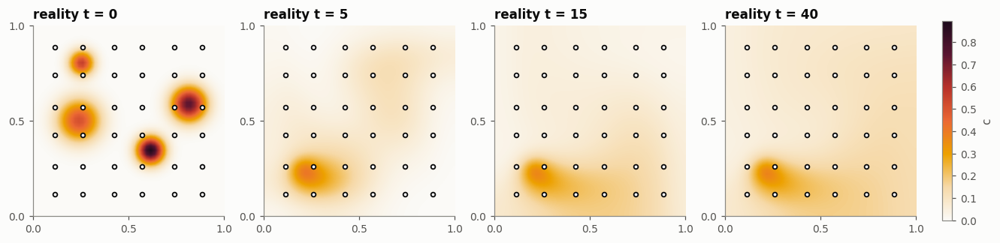

In [12]:
N_GRID, T_END, T_OBS = 48, 40.0, 1.0
KAPPA_TRUE, FLOW_TRUE = 1.5e-3, 0.025
model = AdvDiff2D(n=N_GRID, kappa=KAPPA_TRUE, flow_amplitude=FLOW_TRUE, decay=0.03,
                  kappa_max=5e-3, flow_max=0.06)
X, Y = model.X, model.Y
n_state = N_GRID**2
inlet = gaussian_blob(X, Y, 0.2, 0.25, width=0.04, amp=0.4)
steps_per_obs = int(round(T_OBS / model.dt))
n_cycles = int(round(T_END / T_OBS))

obs_idx, _ = grid_2d(N_GRID, 6)
sens = PointSensors(obs_idx, n_state, noise_std=0.005)
sx, sy = flat_to_xy(obs_idx, N_GRID, model.x)

c_true = random_blobs(X, Y, rng, n_blobs=4)
truth, Yobs = [c_true.copy()], []
for k in range(n_cycles):
    for _ in range(steps_per_obs):
        c_true = model.step(c_true, inlet)
    c_true = c_true + smooth_noise(c_true.shape, rng, 3, 2e-4)   # small unmodelled disturbance
    truth.append(c_true.copy())
    Yobs.append(sens.observe(c_true, rng))
truth, Yobs = np.array(truth), np.array(Yobs)
t_cyc = np.arange(n_cycles + 1) * steps_per_obs * model.dt
print(f"state size {n_state}, dt = {model.dt:.4f}, {steps_per_obs} steps between observations")

fig, axes = viz.snapshot_grid([truth[i] for i in (0, 5, 15, 40)], [f"reality t = {t_cyc[i]:.0f}" for i in (0, 5, 15, 40)],
                              vmin=0, label="c", size=2.8)
for ax in axes.flat:
    viz.sensors_2d(ax, sx, sy, s=14)
plt.show()

## B3. The EnKF loop
The state vector of member $i$ is $[\,c_i\ (2304),\ \log\kappa_i,\ a_i\,]$. We estimate $\log\kappa$
rather than $\kappa$ because it is positive and spans orders of magnitude, which keeps the
Gaussian assumption reasonable.

In [13]:
def init_ensemble(N, rng):
    C0 = np.array([random_blobs(X, Y, rng, n_blobs=4) for _ in range(N)])
    logk = np.log(6e-4) + 0.6 * rng.standard_normal(N)
    flow = 0.015 + 0.007 * rng.standard_normal(N)
    return np.hstack([C0.reshape(N, -1), logk[:, None], flow[:, None]])

def forecast(E, rng, estimate_params=True):
    N = E.shape[0]
    C = E[:, :n_state].reshape(N, N_GRID, N_GRID)
    kappa = np.clip(np.exp(E[:, -2]), 1e-5, 5e-3)[:, None, None]
    flow = np.clip(E[:, -1], 0.0, 0.06)[:, None, None]
    for _ in range(steps_per_obs):
        C = model.step(C, inlet, kappa=kappa, flow=flow)
    C = C + smooth_noise(C.shape, rng, 3, 1e-3)                    # model-error (additive) noise
    E = E.copy()
    E[:, :n_state] = C.reshape(N, -1)
    if estimate_params:                                           # tiny parameter jitter keeps spread alive
        E[:, -2] += 0.02 * rng.standard_normal(N)
        E[:, -1] += 3e-4 * rng.standard_normal(N)
    return E

coords = np.c_[X.ravel(), Y.ravel()]

def run(N=40, assimilate=True, estimate_params=True, loc_radius=0.2, inflation=1.04, seed=0):
    r = np.random.default_rng(seed)
    E = init_ensemble(N, r)
    if not estimate_params:                                       # params frozen at prior mean
        E[:, -2], E[:, -1] = np.log(6e-4), 0.015
    filt = EnKF(obs_idx, sens.noise_std, inflation=inflation,
                loc_radius=loc_radius, coords=coords)
    out = {"mean": [E[:, :n_state].mean(0)], "std": [E[:, :n_state].std(0)],
           "logk": [E[:, -2].copy()], "flow": [E[:, -1].copy()]}
    for k in range(n_cycles):
        E = forecast(E, r, estimate_params)
        if assimilate:
            E = filt.analysis(E, Yobs[k], r)
        out["mean"].append(E[:, :n_state].mean(0))
        out["std"].append(E[:, :n_state].std(0))
        out["logk"].append(E[:, -2].copy())
        out["flow"].append(E[:, -1].copy())
    out = {k: np.array(v) for k, v in out.items()}
    out["mean"] = out["mean"].reshape(-1, N_GRID, N_GRID)
    out["std"] = out["std"].reshape(-1, N_GRID, N_GRID)
    out["rmse"] = np.sqrt(((out["mean"] - truth) ** 2).mean((1, 2)))
    out["spread"] = np.sqrt((out["std"] ** 2).mean((1, 2)))
    return out

t0 = time.time()
runs = {
    "open loop (no data)": run(assimilate=False),
    "EnKF, state only (params fixed, wrong)": run(estimate_params=False),
    "EnKF, joint state + parameters": run(),
}
print(f"3 runs x 40 members in {time.time() - t0:.0f}s")
best = runs["EnKF, joint state + parameters"]

3 runs x 40 members in 19s


## B4. Truth vs. twin: mean, error, and uncertainty maps
Colour scales differ per column: watch the colour-bar ranges of the error and std rows shrink as
the twin converges.

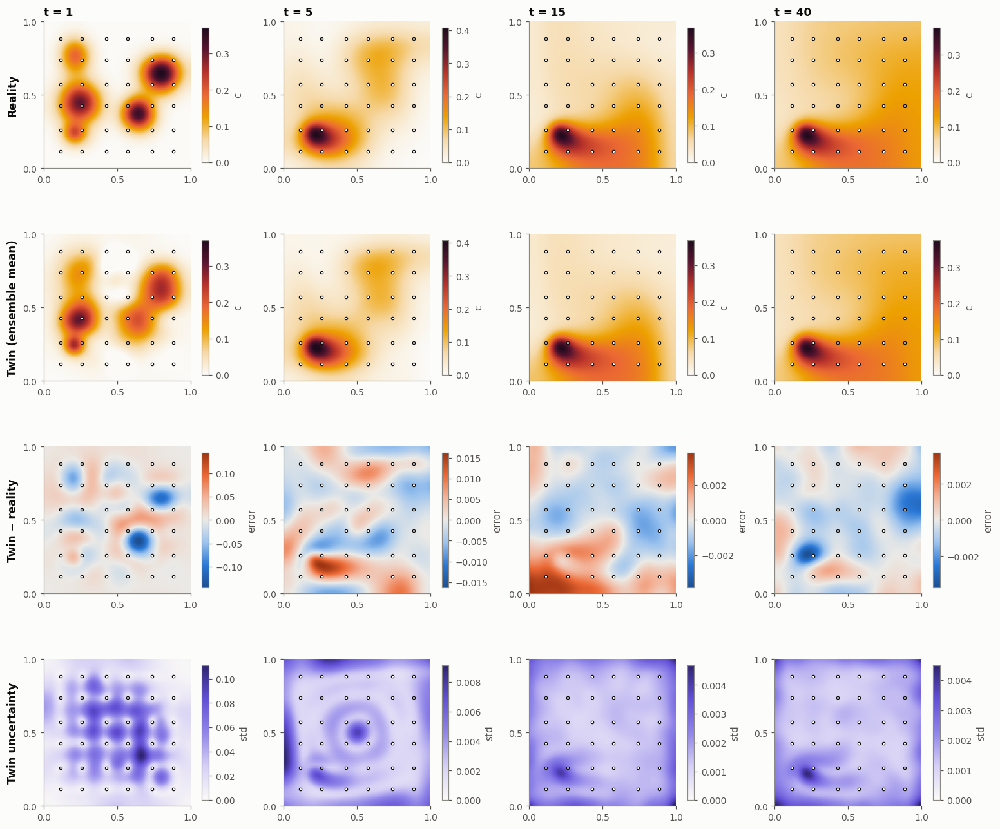

In [14]:
show = [1, 5, 15, 40]
fig, axes = plt.subplots(4, len(show), figsize=(14, 12), constrained_layout=True)
for j, i in enumerate(show):          # each column has its own scale: errors shrink by 100x over time
    vmax = truth[i].max()
    err = best["mean"][i] - truth[i]
    lim = np.abs(err).max()
    viz.field(axes[0, j], truth[i], vmin=0, vmax=vmax, label="c", title=f"t = {t_cyc[i]:.0f}")
    viz.field(axes[1, j], best["mean"][i], vmin=0, vmax=vmax, label="c")
    viz.field(axes[2, j], err, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="error")
    viz.field(axes[3, j], best["std"][i], cmap=viz.UNCERTAINTY, vmin=0, label="std")
    for r in range(4):
        viz.sensors_2d(axes[r, j], sx, sy, s=8, linewidth=0.8)
for r, name in enumerate(["Reality", "Twin (ensemble mean)", "Twin − reality", "Twin uncertainty"]):
    axes[r, 0].set_ylabel(name, fontsize=11, color=viz.INK, fontweight="semibold")
viz.save(fig, "06_enkf_maps.png")
plt.show()

## B5. Error over time, and does the twin know how wrong it is?
A well-tuned ensemble has **spread ≈ RMSE** (dotted ≈ solid). Spread far below error means an
over-confident twin that will ignore its sensors (filter divergence).

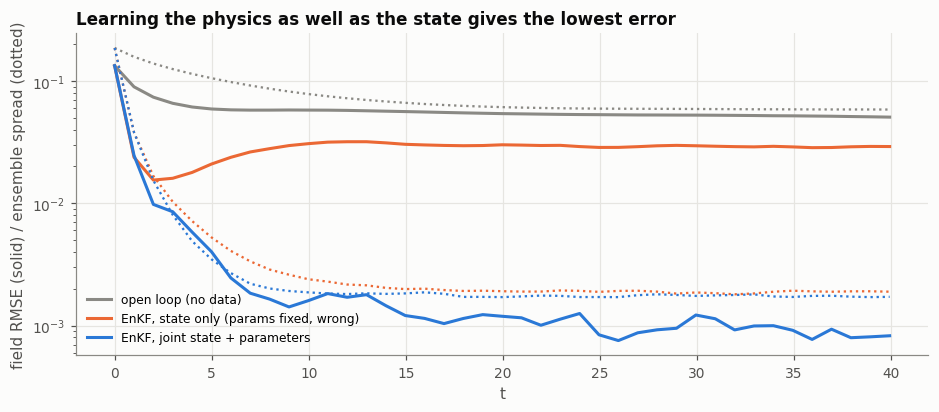

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (name, r) in enumerate(runs.items()):
    col = [viz.MUTED, viz.ORANGE, viz.BLUE][i]
    ax.plot(t_cyc, r["rmse"], color=col, label=f"{name}")
    ax.plot(t_cyc, r["spread"], color=col, ls=":", lw=1.5)
ax.set(xlabel="t", ylabel="field RMSE (solid) / ensemble spread (dotted)", yscale="log",
       title="Learning the physics as well as the state gives the lowest error")
ax.legend(loc="lower left", fontsize=8)
plt.show()

Look at the orange run: its spread (≈0.002) is ~15× smaller than its actual error (≈0.03). With
the wrong physics frozen in, the ensemble is **over-confident**: it trusts its wrong model and
under-weights the sensors. Spread ≪ error is the classic symptom of model error, and a cue that
the twin needs to learn parameters (or needs more model noise).

## B6. The twin learns κ and the pump strength

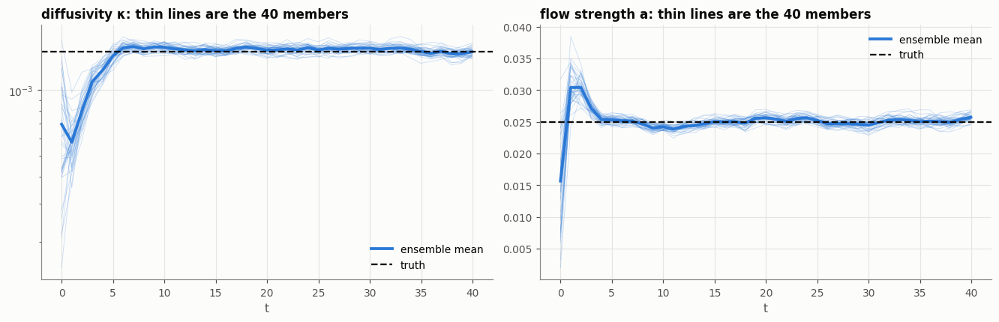

kappa: 1.50e-03 (true 1.5e-03)   a: 0.0257 (true 0.025)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, key, true, tr, lbl in [(axes[0], "logk", KAPPA_TRUE, np.exp, "diffusivity κ"),
                               (axes[1], "flow", FLOW_TRUE, lambda v: v, "flow strength a")]:
    vals = tr(best[key])
    ax.plot(t_cyc, vals, color=viz.TWIN, lw=0.5, alpha=0.25)
    ax.plot(t_cyc, vals.mean(1), color=viz.TWIN, lw=2.5, label="ensemble mean")
    ax.axhline(true, color=viz.TRUTH, ls="--", lw=1.5, label="truth")
    ax.set(xlabel="t", title=f"{lbl}: thin lines are the 40 members")
    if key == "logk":
        ax.set_yscale("log")
    ax.legend()
plt.show()
print(f"kappa: {np.exp(best['logk'][-1]).mean():.2e} (true {KAPPA_TRUE:.1e})   "
      f"a: {best['flow'][-1].mean():.4f} (true {FLOW_TRUE})")

## B7. Localization: why a 40-member ensemble needs help
With $N=40$ samples, the estimated correlation between two distant points is pure sampling noise of
size $\sim 1/\sqrt{N}\approx0.16$. Those **spurious correlations** let a sensor in one corner
"correct" the opposite corner. **Localization** multiplies the covariance by a taper
$\rho(d)$ (Gaspari-Cohn) that goes to zero beyond a cut-off distance.

Below: the Kalman gain for one sensor, i.e. how much an innovation at that sensor moves each grid
cell, with and without localization (small ensemble, $N=15$). Then we run a full
twin with only $N=8$ members, with and without localization.

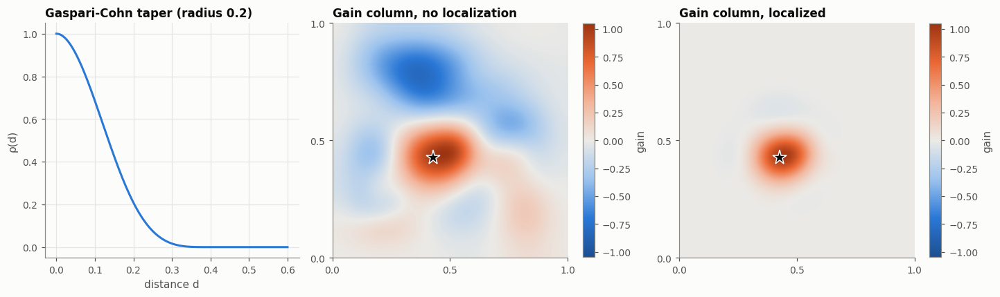

In [17]:
r_ = np.random.default_rng(5)
E = forecast(forecast(init_ensemble(15, r_), r_), r_)
j_obs = 14
gains = []
for loc in [None, 0.2]:
    A = E - E.mean(0)
    HA = A[:, obs_idx]
    PHt = A.T @ HA / 14
    if loc:
        d = np.linalg.norm(coords - coords[obs_idx[j_obs]], axis=1)
        PHt[:n_state, j_obs] *= gaspari_cohn(d / loc)
    gains.append(PHt[:n_state, j_obs].reshape(N_GRID, N_GRID) / (PHt[obs_idx[j_obs], j_obs] + sens.noise_std**2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
dd = np.linspace(0, 0.6, 200)
axes[0].plot(dd, gaspari_cohn(dd / 0.2), color=viz.TWIN)
axes[0].set(xlabel="distance d", ylabel="ρ(d)", title="Gaspari-Cohn taper (radius 0.2)")
lim = np.abs(gains[0]).max()
for ax, g, ttl in zip(axes[1:], gains, ["Gain column, no localization", "Gain column, localized"]):
    viz.field(ax, g, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="gain", title=ttl)
    ax.plot(sx[j_obs], sy[j_obs], "*", color=viz.INK, ms=14, mec="white")
plt.show()

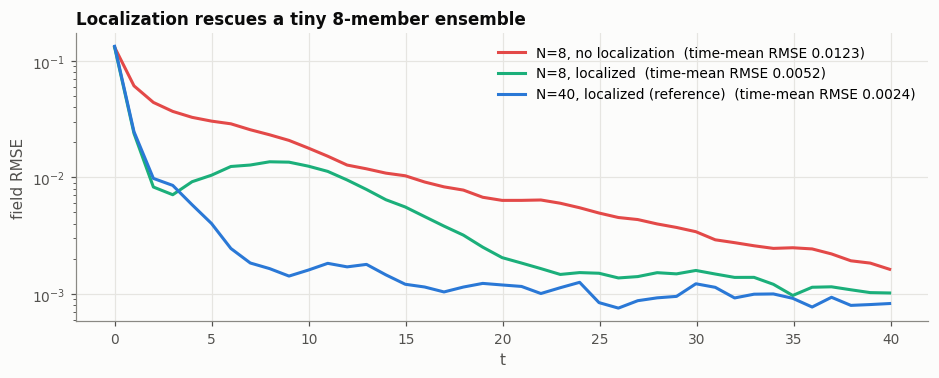

2s


In [18]:
t0 = time.time()
small = {f"N=8, {'localized' if loc else 'no localization'}": run(N=8, loc_radius=loc, seed=3)
         for loc in [None, 0.2]}
small["N=40, localized (reference)"] = best
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, r) in enumerate(small.items()):
    ax.plot(t_cyc, r["rmse"], color=[viz.RED, viz.AQUA, viz.BLUE][i],
            label=f"{name}  (time-mean RMSE {r['rmse'][1:].mean():.4f})")
ax.set(xlabel="t", ylabel="field RMSE", yscale="log", title="Localization rescues a tiny 8-member ensemble")
ax.legend()
plt.show()
print(f"{time.time() - t0:.0f}s")

## B8. Watch the twin converge

In [19]:
anim = viz.animate_2d([truth, best["mean"], best["std"]], t_cyc,
                      ["Reality", "Twin (ensemble mean)", "Twin uncertainty (std)"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.UNCERTAINTY],
                      vlims=[(0, truth[5:].max()), (0, truth[5:].max()), (0, 0.03)], sensors=(sx, sy), size=3.4, interval=200)
HTML(anim.to_jshtml())

---
# Chapter recap
* 2D transport = advection + diffusion + decay + sources. The **Péclet number** sets the structure.
* Finite volumes conserve mass exactly, but upwinding adds numerical diffusion.
* The **EnKF** swaps the covariance matrix for an ensemble of nonlinear model runs. It scales to
  large fields and learns parameters through ensemble correlations.
* **Inflation** stops the ensemble collapsing; **localization** removes the false long-range
  correlations that a small ensemble produces.
* Always check spread vs error: a twin whose spread is much smaller than its real error is
  over-confident.

## Quick quiz
1. Pe = 500. Do you expect smooth blobs or thin filaments?
2. Why does an ensemble of 8 members produce correlations between far-apart points that aren't real?
3. The ensemble spread of $\kappa$ shrinks to almost zero in 10 steps but the estimate is wrong. What happened, and what fixes it?

<details><summary>Answers</summary>

1. Thin filaments: advection dominates.
2. Sampling noise. Any two variables have a random sample correlation of order $1/\sqrt{N}$ even
   when the true correlation is zero.
3. Ensemble collapse: the filter became over-confident and now ignores the data. Add inflation,
   or parameter noise, and check the NIS.
</details>

## Exercises
1. Move the inlet next to a wall. How do the probe arrival times change?
2. Run the EnKF with N = 15 and no localization. What happens to the κ estimate?
3. Turn inflation off (1.0). Plot the spread of κ over time.

**Next: Chapter 4.** The EnKF needs dozens of full model runs every step. Reduced-order models
make the physics up to 100× faster, enough to run the twin in real time.